⚡ Modelos de Madrid carregados da memória do disco!

 1. AVALIAÇÃO ZERO-SHOT
Performance Zero-Shot: Macro F1 = 0.5111

 2. EXPERIMENTAÇÃO FEW-SHOT (FINE-TUNING COM AMSTERDÃO)
Few-Shot (  5 pixels/classe) | Macro F1 Média: 0.4929 (± 0.0240)
Few-Shot ( 10 pixels/classe) | Macro F1 Média: 0.5228 (± 0.0281)
Few-Shot ( 25 pixels/classe) | Macro F1 Média: 0.6204 (± 0.0115)
Few-Shot ( 50 pixels/classe) | Macro F1 Média: 0.6394 (± 0.0126)
Few-Shot (100 pixels/classe) | Macro F1 Média: 0.6679 (± 0.0085)
Few-Shot (200 pixels/classe) | Macro F1 Média: 0.6820 (± 0.0112)


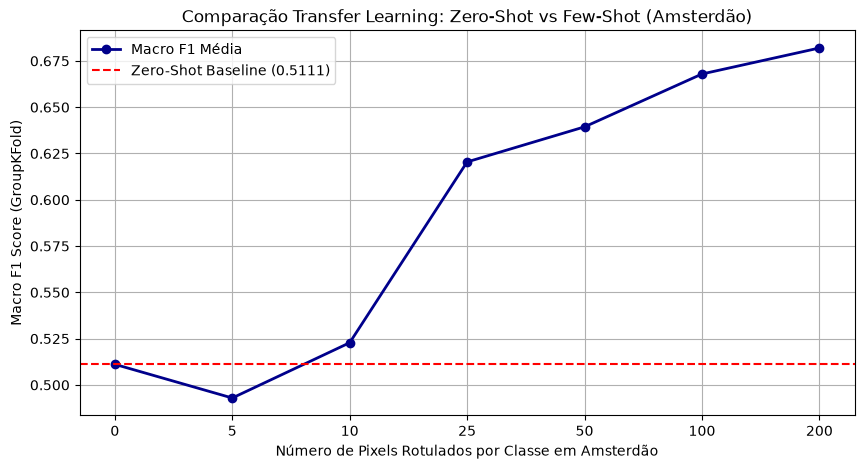

In [1]:
#By Eufrasio
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

# 1. CARREGAMENTO DOS MODELOS PRÉ-TREINADOS DE MADRID.
models = joblib.load('/shared/mauro/Building_Age_Classification/data/preprocessed/madrid_models.pkl')
le = joblib.load('/shared/mauro/Building_Age_Classification/data/preprocessed/label_encoder.pkl')

print("Modelos de Madrid carregados da memória do disco!")

# 2. CARREGAR DADOS DE AMSTERDÃO
FILE_PATH = "/shared/mauro/Building_Age_Classification/data/preprocessed/preprocessed_data.pkl"
data = pd.read_pickle(FILE_PATH)

X_amsterdam = data['X_amsterdam']
y_raw_ams = data['y_amsterdam']
pixel_ids_ams = data['pixel_ids_amsterdam']

y_amsterdam = le.transform(y_raw_ams)
spatial_groups_ams = pd.Series(pixel_ids_ams[:, 0].astype(str) + "_" + pixel_ids_ams[:, 1].astype(str))
num_classes = len(np.unique(y_amsterdam))

# ==============================================================================
#  AVALIAÇÃO ZERO-SHOT (MADRID -> AMSTERDÃO DIRETO)
# ==============================================================================
print("\n" + "="*60)
print(" 1. AVALIAÇÃO ZERO-SHOT")
print("="*60)

zero_shot_probs = np.zeros((len(X_amsterdam), num_classes))
for model in models:
    zero_shot_probs += model.predict(X_amsterdam) / len(models)

zero_shot_preds = np.argmax(zero_shot_probs, axis=1)
zero_shot_f1 = f1_score(y_amsterdam, zero_shot_preds, average='macro')

print(f"Performance Zero-Shot: Macro F1 = {zero_shot_f1:.4f}\n")

# ==============================================================================
#  FEW-SHOT (5, 10, 25, 50, 100, 200 pixels/classe)
# ==============================================================================
print("="*60)
print(" FEW-SHOT (FINE-TUNING COM AMSTERDÃO)")
print("="*60)

sample_sizes_few_shot = [5, 10, 25, 50, 100, 200]
transfer_results = [{'Amostras/Classe': 0, 'Macro_F1_Mean': zero_shot_f1, 'Macro_F1_Std': 0.0}]

FT_PARAMS = {
    'objective': 'multiclass',
    'num_class': num_classes,
    'boosting_type': 'gbdt',
    'metric': 'multi_logloss',
    'learning_rate': 0.01,
    'num_leaves': 31,
    'verbose': -1,
    'random_state': 42,
    'n_jobs': -1
}

for k_samples in sample_sizes_few_shot:
    gkf_ams = GroupKFold(n_splits=5)
    fold_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf_ams.split(X_amsterdam, y_amsterdam, spatial_groups_ams)):
        X_tr_fold, y_tr_fold = X_amsterdam[train_idx], y_amsterdam[train_idx]
        X_va_fold, y_va_fold = X_amsterdam[val_idx], y_amsterdam[val_idx]
        
        np.random.seed(42 + fold)
        few_shot_idx = []
        for cls in np.unique(y_tr_fold):
            cls_indices = np.where(y_tr_fold == cls)[0]
            sampled = np.random.choice(cls_indices, size=min(len(cls_indices), k_samples), replace=False)
            few_shot_idx.extend(sampled)
            
        X_few = X_tr_fold[few_shot_idx]
        y_few = y_tr_fold[few_shot_idx]
        
        base_model = models[fold]
        
        ams_train_data = lgb.Dataset(X_few, label=y_few)
        ams_val_data = lgb.Dataset(X_va_fold, label=y_va_fold, reference=ams_train_data)
        
        ft_model = lgb.train(
            FT_PARAMS,
            ams_train_data,
            num_boost_round=150,
            init_model=base_model,
            valid_sets=[ams_train_data, ams_val_data],
            callbacks=[lgb.early_stopping(stopping_rounds=15, verbose=False)]
        )
        
        preds_ams = np.argmax(ft_model.predict(X_va_fold, num_iteration=ft_model.best_iteration), axis=1)
        score = f1_score(y_va_fold, preds_ams, average='macro')
        fold_scores.append(score)
        
    mean_f1 = np.mean(fold_scores)
    std_f1 = np.std(fold_scores)
    transfer_results.append({'Amostras/Classe': k_samples, 'Macro_F1_Mean': mean_f1, 'Macro_F1_Std': std_f1})
    
    print(f"Few-Shot ({k_samples:>3} pixels/classe) | Macro F1 Média: {mean_f1:.4f} (± {std_f1:.4f})")

# 3. GRÁFICO FINAL
res_df = pd.DataFrame(transfer_results)

plt.figure(figsize=(10, 5))
plt.plot(res_df['Amostras/Classe'].astype(str), res_df['Macro_F1_Mean'], marker='o', linewidth=2, color='darkblue', label='Macro F1 Média')
plt.axhline(y=zero_shot_f1, color='r', linestyle='--', label=f'Zero-Shot Baseline ({zero_shot_f1:.4f})')
plt.title('Comparação Transfer Learning: Zero-Shot vs Few-Shot (Amsterdão)')
plt.xlabel('Número de Pixels Rotulados por Classe em Amsterdão')
plt.ylabel('Macro F1 Score (GroupKFold)')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
from sklearn.metrics import classification_report

# 1. TABELA DETALHADA PARA O ZERO-SHOT (0 amostras de Amsterdão)
print("="*65)
print(" AMSTERDAN ZERO-SHOT")
print("="*65)

# Converter rótulos numéricos para os nomes originais das classes se disponíveis
target_names = [str(cls) for cls in le.classes_]

print(classification_report(y_amsterdam, zero_shot_preds, target_names=target_names, digits=4))


# 2. TABELA DETALHADA PARA O FEW-SHOT (Exemplo com a melhor configuração, ex: 200 amostras)
# Nota: Guarda as predições do último fold do K-Shot para imprimir o relatório completo
print("="*65)
print(" AMSTERDAN FEW-SHOT")
print("="*65)

# Exemplo de chamada para as predições do Few-Shot
print(classification_report(y_va_fold, preds_ams, target_names=target_names, digits=4))

 AMSTERDAN ZERO-SHOT
              precision    recall  f1-score   support

           1     0.5609    0.6353    0.5958      7568
           2     0.4371    0.6239    0.5140      8802
           3     0.8156    0.2360    0.3661      6745
           4     0.5662    0.5711    0.5686      2877

    accuracy                         0.5207     25992
   macro avg     0.5949    0.5166    0.5111     25992
weighted avg     0.5856    0.5207    0.5055     25992

 AMSTERDAN FEW-SHOT
              precision    recall  f1-score   support

           1     0.7259    0.7381    0.7319      1550
           2     0.6501    0.6402    0.6451      1762
           3     0.7528    0.6515    0.6985      1323
           4     0.5782    0.7620    0.6575       563

    accuracy                         0.6855      5198
   macro avg     0.6768    0.6979    0.6833      5198
weighted avg     0.6911    0.6855    0.6859      5198

